# Ensemble & Model Comparison: CNN vs ViT

This notebook compares the performance of the CNN and ViT (DeiT) models, and evaluates an ensemble of both using the test set. You will:
- Load probability predictions and labels from previous evaluations
- Evaluate each model's test metrics and show detailed classification reports
- Visualize ROC curves and confusion matrices
- Build and evaluate a simple ensemble (mean of predicted probabilities)

_**Each section is fully commented for clarity.**_

## Preparation

Import the necessary libraries and load saved probability predictions and true labels from disk. These NumPy arrays were generated in the individual model evaluation notebooks.

Assertions ensure the data shapes match and are compatible for comparison.

In [1]:
import os
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import DataLoader
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from timm import create_model
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from tqdm import tqdm

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score,
    matthews_corrcoef, roc_curve, ConfusionMatrixDisplay
)

# Load saved probability predictions and labels
cnn_probs = np.load("output/comparison/cnn_probs.npy")
vit_probs = np.load("output/comparison/vit_probs.npy")
y_true = np.load("output/comparison/true_labels.npy")

assert cnn_probs.shape == vit_probs.shape
assert len(y_true) == len(cnn_probs)
print("cnn_probs:", cnn_probs.shape)
print("vit_probs:", vit_probs.shape)
print("y_true:", y_true.shape)


c:\Users\Utilizador\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cnn_probs: (11997,)
vit_probs: (11997,)
y_true: (11997,)


## Define Evaluation Function

The function `evaluate_model` takes true labels and predicted probabilities, applies a 0.5 threshold for binary prediction, and prints a complete classification report and confusion matrix. It also computes and returns key metrics for later comparison.

In [2]:
def evaluate_model(name, y_true, y_scores):
    y_pred = (y_scores >= 0.5).astype(int)

    print(f"=== {name} ===")
    print("Classification Report:\n", classification_report(y_true, y_pred, target_names=["fake", "real"]))
    print("Confusion Matrix:\n", confusion_matrix(y_true, y_pred))

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1 Score": f1_score(y_true, y_pred),
        "ROC AUC": roc_auc_score(y_true, y_scores),
        "Matthews Correlation Coefficient": matthews_corrcoef(y_true, y_pred)
    }

    for metric, value in metrics.items():
        print(f"{metric}: {value:.4f}")

    print("\n" + "="*40 + "\n")
    return y_pred, metrics


## Evaluate Both Models

Call the evaluation function for both CNN and ViT (DeiT) models. The returned metrics will be used for tabular comparison.

In [3]:
cnn_pred, cnn_metrics = evaluate_model("CNN", y_true, cnn_probs)


=== CNN ===
Classification Report:
               precision    recall  f1-score   support

        fake       0.95      0.93      0.94      6000
        real       0.93      0.95      0.94      5997

    accuracy                           0.94     11997
   macro avg       0.94      0.94      0.94     11997
weighted avg       0.94      0.94      0.94     11997

Confusion Matrix:
 [[5566  434]
 [ 323 5674]]
Accuracy: 0.9369
Precision: 0.9289
Recall: 0.9461
F1 Score: 0.9375
ROC AUC: 0.9839
Matthews Correlation Coefficient: 0.8740




In [4]:
vit_pred, vit_metrics = evaluate_model("ViT", y_true, vit_probs)

=== ViT ===
Classification Report:
               precision    recall  f1-score   support

        fake       0.95      0.92      0.93      6000
        real       0.92      0.95      0.93      5997

    accuracy                           0.93     11997
   macro avg       0.93      0.93      0.93     11997
weighted avg       0.93      0.93      0.93     11997

Confusion Matrix:
 [[5500  500]
 [ 302 5695]]
Accuracy: 0.9331
Precision: 0.9193
Recall: 0.9496
F1 Score: 0.9342
ROC AUC: 0.9830
Matthews Correlation Coefficient: 0.8668




## Metrics Comparison Table

Display the most important metrics for both models side-by-side in a Pandas DataFrame for quick comparison.

In [5]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Metric": list(cnn_metrics.keys()),
    "CNN": list(cnn_metrics.values()),
    "ViT": list(vit_metrics.values())
})

comparison_df.set_index("Metric", inplace=True)
comparison_df.style.format("{:.4f}").highlight_max(axis=1)


,CNN,ViT
Metric,,
Accuracy,0.9369,0.9331
Precision,0.9289,0.9193
Recall,0.9461,0.9496
F1 Score,0.9375,0.9342
ROC AUC,0.9839,0.9830
Matthews Correlation Coefficient,0.8740,0.8668


## ROC Curve Comparison

Plot ROC curves for both models on the same plot for direct visual comparison. The AUC summarizes overall discrimination ability.

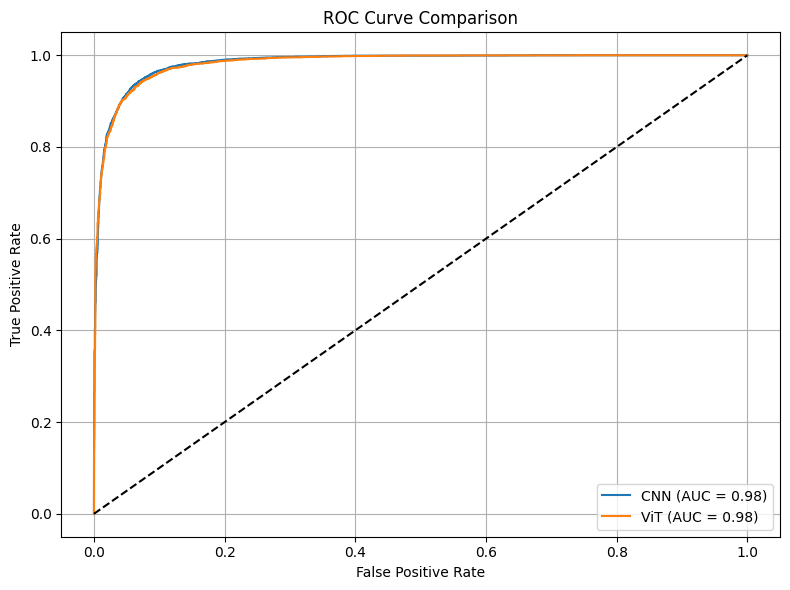

In [6]:
fpr_cnn, tpr_cnn, _ = roc_curve(y_true, cnn_probs)
fpr_vit, tpr_vit, _ = roc_curve(y_true, vit_probs)

plt.figure(figsize=(8, 6))
plt.plot(fpr_cnn, tpr_cnn, label=f"CNN (AUC = {cnn_metrics['ROC AUC']:.2f})")
plt.plot(fpr_vit, tpr_vit, label=f"ViT (AUC = {vit_metrics['ROC AUC']:.2f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


## Confusion Matrices for Both Models

Plot confusion matrices for CNN and ViT side-by-side to visualize prediction breakdown by class.

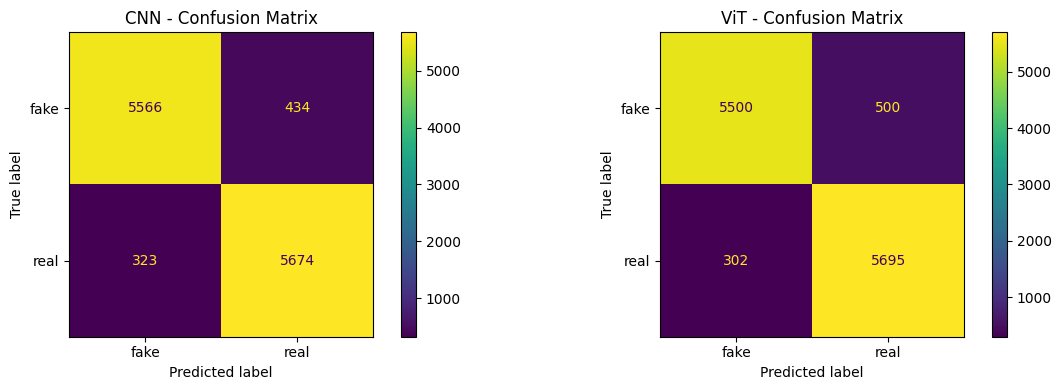

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay.from_predictions(y_true, cnn_pred, display_labels=["fake", "real"], ax=axes[0])
axes[0].set_title("CNN - Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(y_true, vit_pred, display_labels=["fake", "real"], ax=axes[1])
axes[1].set_title("ViT - Confusion Matrix")

plt.tight_layout()
plt.show()


## Load Models for Ensemble Inference

Load both trained CNN and ViT models from disk, preparing them for ensemble prediction on the test set. The architectures must match those used during training.

In [8]:
# Load EfficientNet B0 for CNN
cnn_model = efficientnet_b0(weights=None)
cnn_model.classifier[1] = nn.Linear(cnn_model.classifier[1].in_features, 2)
cnn_model.load_state_dict(torch.load("checkpoints/CNN/model_final.pth", map_location=torch.device('cpu')))
cnn_model = cnn_model.eval()

# Load DeiT (Vision Transformer)
vit_model = create_model("deit_tiny_patch16_224", pretrained=False, num_classes=2)
vit_model.load_state_dict(torch.load("checkpoints/DeiT/deit_final.pth", map_location=torch.device('cpu')))
vit_model = vit_model.eval()


## Load Test Set for Ensemble Evaluation

Load the test dataset and create a DataLoader for single-image batch processing, as ensemble prediction is typically done per-sample.

In [9]:
test_dataset = torch.load("data/processed/test_dataset.pt", weights_only=False)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)

## Ensemble Evaluation

For each test sample, predict with both models, average their probabilities (simple mean ensemble), and choose the final class by argmax. Accumulate the results for final metrics and confusion matrix.

In [10]:
all_preds = []
all_probs = []
all_labels = []

softmax = nn.Softmax(dim=1)

with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Ensemble Evaluation"):
        # Inference for each image (CPU for simplicity here)
        out_cnn = softmax(cnn_model(imgs))
        out_vit = softmax(vit_model(imgs))

        # Ensemble: average probabilities
        ensemble_probs = (out_cnn + out_vit) / 2
        ensemble_pred = torch.argmax(ensemble_probs, dim=1)

        all_probs.append(ensemble_probs[:, 1].item())  # probability of 'real'
        all_preds.append(ensemble_pred.item())
        all_labels.append(labels.item())


Ensemble Evaluation:   8%|▊         | 957/11997 [01:57<33:56,  5.42it/s]  c:\Users\Utilizador\AppData\Local\Programs\Python\Python313\Lib\site-packages\PIL\Image.py:1043: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Ensemble Evaluation:  64%|██████▍   | 7737/11997 [18:09<31:15,  2.27it/s]  c:\Users\Utilizador\AppData\Local\Programs\Python\Python313\Lib\site-packages\PIL\Image.py:3442: DecompressionBombWarning: Image size (143040000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
Ensemble Evaluation:  65%|██████▍   | 7739/11997 [18:11<41:51,  1.70it/s]c:\Users\Utilizador\AppData\Local\Programs\Python\Python313\Lib\site-packages\PIL\Image.py:3442: DecompressionBombWarning: Image size (121554000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
Ensemble Evaluation: 100%|██████████| 11997/11997 [30:20<00:00,  6.59it/s] 


## Ensemble Classification Report and Confusion Matrix

Display classification details and confusion matrix for the ensemble predictions.

Ensemble Classification Report:
              precision    recall  f1-score   support

        fake       0.96      0.92      0.94      6000
        real       0.93      0.96      0.94      5997

    accuracy                           0.94     11997
   macro avg       0.94      0.94      0.94     11997
weighted avg       0.94      0.94      0.94     11997



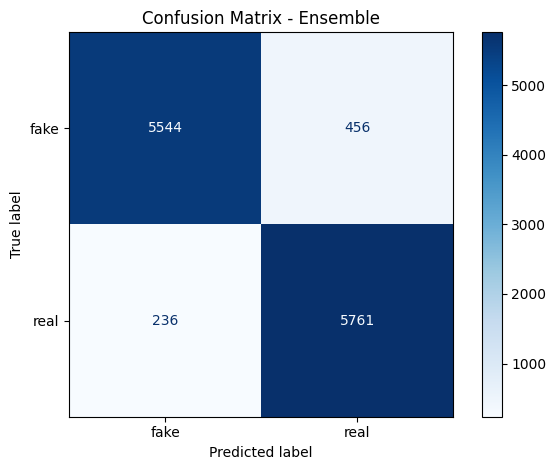

In [11]:
print("Ensemble Classification Report:")
print(classification_report(all_labels, all_preds, target_names=["fake", "real"]))

cm = confusion_matrix(all_labels, all_preds)
ConfusionMatrixDisplay(cm, display_labels=["fake", "real"]).plot(cmap="Blues")
plt.title("Confusion Matrix - Ensemble")
plt.tight_layout()
plt.show()
